In [22]:
print(df["Time"].describe())

count    284807.000000
mean      94813.859575
std       47488.145955
min           0.000000
25%       54201.500000
50%       84692.000000
75%      139320.500000
max      172792.000000
Name: Time, dtype: float64


In [23]:
df["Hour"] = (df["Time"] / 3600) % 24

df[["Time", "Hour", "Class"]].head()

,Time,Hour,Class
0,0.0,0.000000,0
1,0.0,0.000000,0
2,1.0,0.000278,0
3,1.0,0.000278,0
4,2.0,0.000556,0


In [24]:
hourly_fraud = df.groupby("Hour")["Class"].agg(
    transactions="count",
    frauds="sum"
)

hourly_fraud["fraud_rate"] = (
    hourly_fraud["frauds"] / hourly_fraud["transactions"] * 100
)

hourly_fraud.head(24)

,transactions,frauds,fraud_rate
Hour,,,
0.000000,3,0,0.0
0.000278,2,0,0.0
0.000278,4,0,0.0
0.000556,3,0,0.0
0.000556,2,0,0.0
0.000833,1,0,0.0
0.001111,1,0,0.0
0.001111,1,0,0.0
0.001389,1,0,0.0


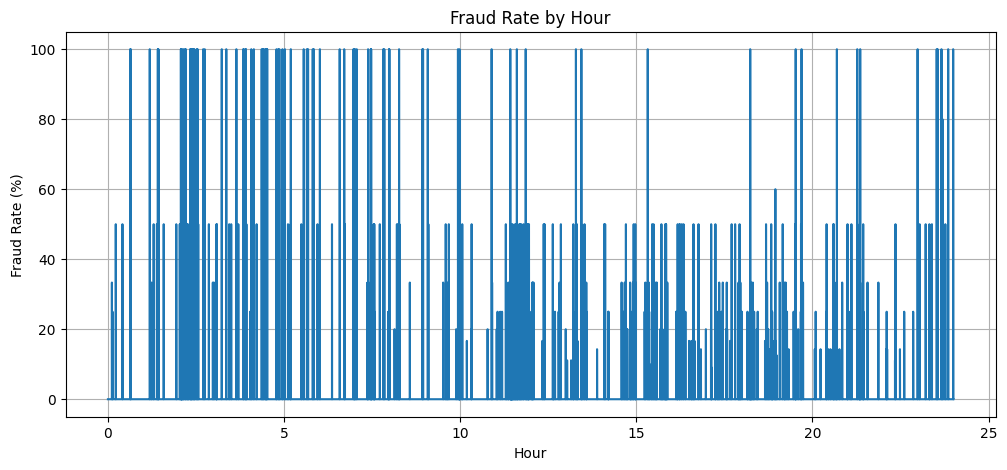

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_fraud.index,
    hourly_fraud["fraud_rate"]
)

plt.xlabel("Hour")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Hour")
plt.grid()

plt.show()

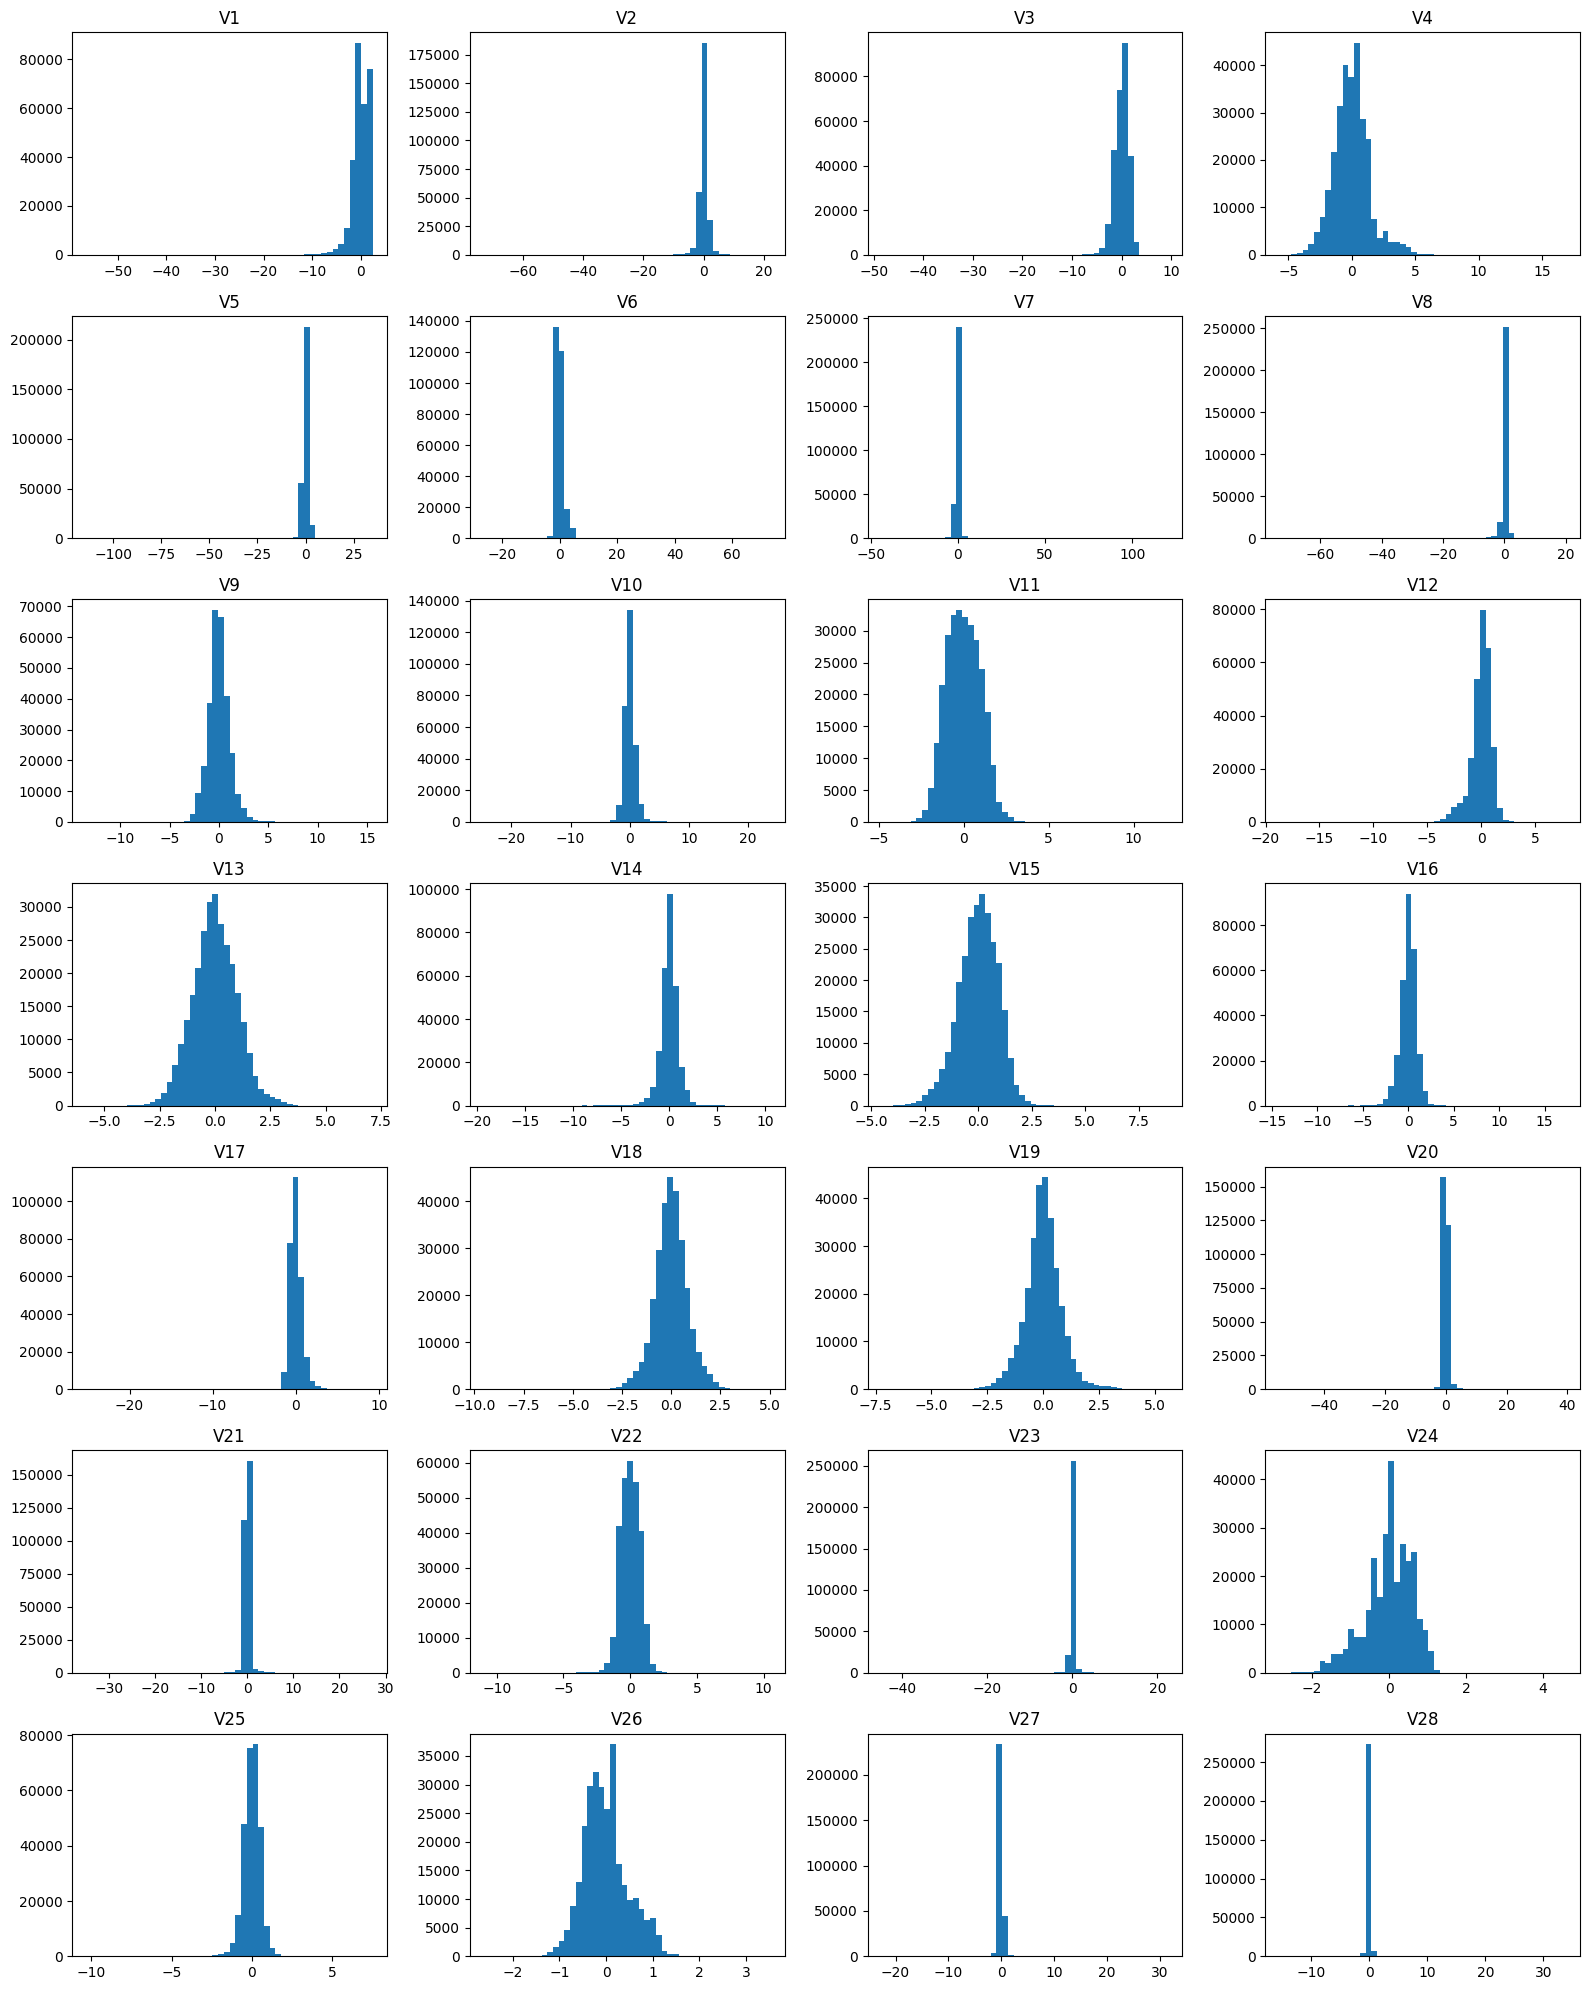

In [26]:
fig, axes = plt.subplots(7, 4, figsize=(16, 20))

for i, col in enumerate([f"V{i}" for i in range(1, 29)]):
    axes.flat[i].hist(df[col], bins=50)
    axes.flat[i].set_title(col)

plt.tight_layout()
plt.show()

In [27]:
correlations = df.corr(numeric_only=True)["Class"].sort_values(
    key=abs,
    ascending=False
)

print(correlations)

Class     1.000000
V17      -0.326481
V14      -0.302544
V12      -0.260593
V10      -0.216883
V16      -0.196539
V3       -0.192961
V7       -0.187257
V11       0.154876
V4        0.133447
V18      -0.111485
V1       -0.101347
V9       -0.097733
V5       -0.094974
V2        0.091289
V6       -0.043643
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
Hour     -0.017082
Time     -0.012323
V28       0.009536
V24      -0.007221
Amount    0.005632
V13      -0.004570
V26       0.004455
V15      -0.004223
V25       0.003308
V23      -0.002685
V22       0.000805
Name: Class, dtype: float64


In [28]:
correlations.head(10)

,Class
Class,1.000000
V17,-0.326481
V14,-0.302544
V12,-0.260593
V10,-0.216883
V16,-0.196539
V3,-0.192961
V7,-0.187257
V11,0.154876
V4,0.133447


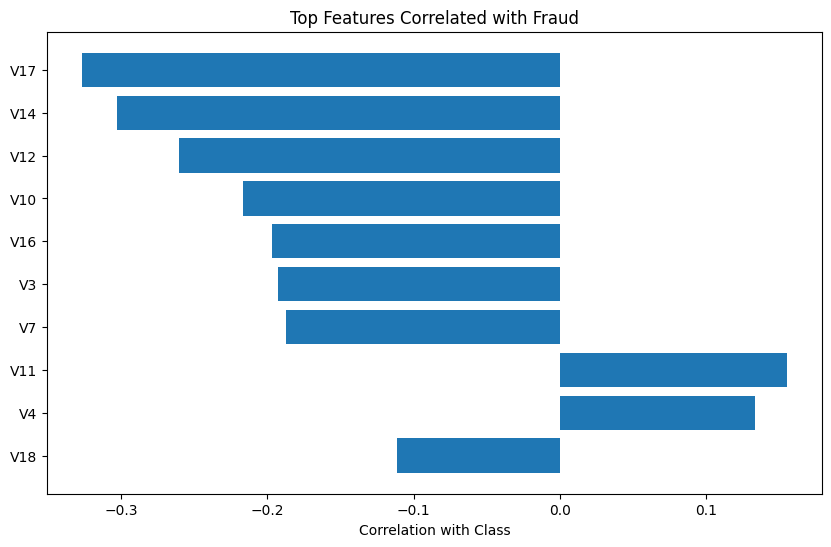

In [29]:
top_features = correlations.index[1:11]

plt.figure(figsize=(10, 6))

plt.barh(
    top_features[::-1],
    correlations[top_features][::-1]
)

plt.xlabel("Correlation with Class")
plt.title("Top Features Correlated with Fraud")

plt.show()

In [30]:
# How many duplicated rows are there?
print("Duplicate rows:", df.duplicated().sum())

# How many unique rows?
print("Unique rows:", df.drop_duplicates().shape[0])

Duplicate rows: 1081
Unique rows: 283726


In [31]:
# Look only at duplicated rows
dupes = df[df.duplicated(keep=False)].sort_values(
    by=list(df.columns)
)

print("Total rows involved in duplicate groups:", len(dupes))

# Check class distribution among duplicated rows
print(dupes["Class"].value_counts())

Total rows involved in duplicate groups: 1854
Class
0    1822
1      32
Name: count, dtype: int64


In [32]:
feature_cols = [col for col in df.columns if col != "Class"]

duplicate_label_check = (
    df.groupby(feature_cols)["Class"]
      .nunique()
)

print(
    "Duplicate feature groups with conflicting Class labels:",
    (duplicate_label_check > 1).sum()
)

Duplicate feature groups with conflicting Class labels: 0


In [33]:
df_unique = df.drop_duplicates()

print("Original shape:", df.shape)
print("After deduplication:", df_unique.shape)

print("\nOriginal class distribution:")
print(df["Class"].value_counts())

print("\nAfter deduplication:")
print(df_unique["Class"].value_counts())

print("\nFraud rate after deduplication:")
print(df_unique["Class"].mean() * 100)

Original shape: (284807, 32)
After deduplication: (283726, 32)

Original class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

After deduplication:
Class
0    283253
1       473
Name: count, dtype: int64

Fraud rate after deduplication:
0.1667101358352777


In [34]:
print(
    "Fraud duplicates:",
    df[df.duplicated(keep=False) & (df["Class"] == 1)].shape[0]
)

Fraud duplicates: 32


In [36]:
# Create clean dataset by removing exact duplicate rows
df_clean = df.drop_duplicates().copy()

print("Original shape:", df.shape)
print("Clean shape:", df_clean.shape)

print("\nClass distribution:")
print(df_clean["Class"].value_counts())

print("\nClass percentage:")
print(df_clean["Class"].value_counts(normalize=True) * 100)

Original shape: (284807, 32)
Clean shape: (283726, 32)

Class distribution:
Class
0    283253
1       473
Name: count, dtype: int64

Class percentage:
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


In [37]:
print(df_clean.groupby("Class")["Amount"].describe())

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      283253.0   88.413575  250.379023  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.871860  260.211041  0.0  1.00   9.82  105.89   2125.87


In [38]:
correlations = (
    df_clean
    .corr(numeric_only=True)["Class"]
    .sort_values(key=abs, ascending=False)
)

print(correlations.head(11))

Class    1.000000
V17     -0.313498
V14     -0.293375
V12     -0.250711
V10     -0.206971
V16     -0.187186
V3      -0.182322
V7      -0.172347
V11      0.149067
V4       0.129326
V18     -0.105340
Name: Class, dtype: float64


In [39]:
amount_stats = df_clean.groupby("Class")["Amount"].describe()
amount_stats

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


In [40]:
print("Genuine median:",
      df_clean[df_clean["Class"] == 0]["Amount"].median())

print("Fraud median:",
      df_clean[df_clean["Class"] == 1]["Amount"].median())

print("Genuine mean:",
      df_clean[df_clean["Class"] == 0]["Amount"].mean())

print("Fraud mean:",
      df_clean[df_clean["Class"] == 1]["Amount"].mean())

Genuine median: 22.0
Fraud median: 9.82
Genuine mean: 88.41357475472456
Fraud mean: 123.87186046511628


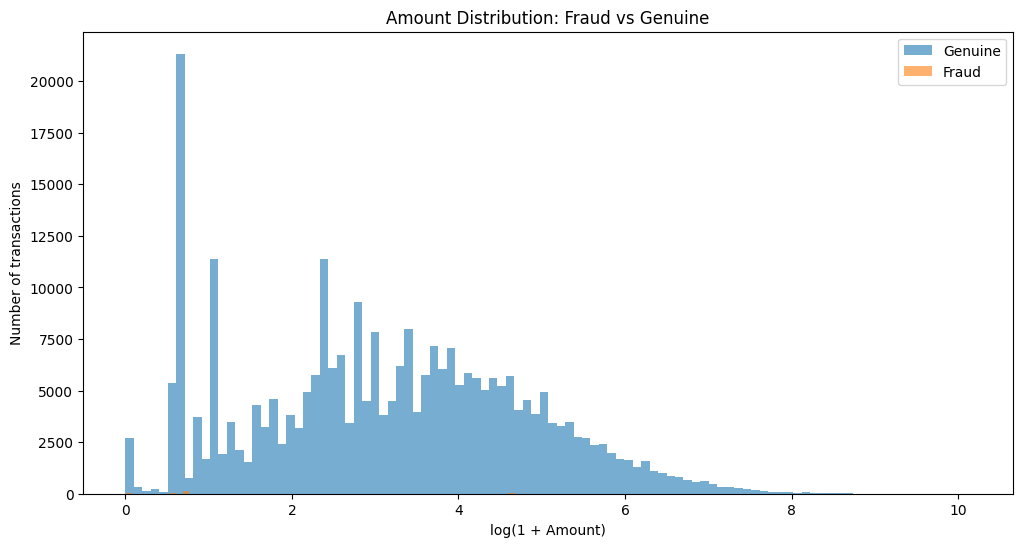

In [41]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.hist(
    np.log1p(df_clean.loc[df_clean["Class"] == 0, "Amount"]),
    bins=100,
    alpha=0.6,
    label="Genuine"
)

plt.hist(
    np.log1p(df_clean.loc[df_clean["Class"] == 1, "Amount"]),
    bins=100,
    alpha=0.6,
    label="Fraud"
)

plt.xlabel("log(1 + Amount)")
plt.ylabel("Number of transactions")
plt.title("Amount Distribution: Fraud vs Genuine")
plt.legend()

plt.show()

In [42]:
df_clean["Time"].describe()

,Time
count,283726.000000
mean,94811.077600
std,47481.047891
min,0.000000
25%,54204.750000
50%,84692.500000
75%,139298.000000
max,172792.000000
